# Chapter 9 — Text Processing and Multiclass Classification

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Diperkirakan 80–90% data di dunia nyata bersifat **tidak terstruktur** (*unstructured*): teks, gambar, audio, video. Algoritma *machine learning* klasik di scikit-learn hanya dapat bekerja dengan matriks angka, sehingga teks mentah harus lebih dulu diubah menjadi representasi numerik. Chapter ini membahas seluruh alur kerja klasifikasi teks: **pra-pemrosesan dan tokenisasi**, **vektorisasi** (Bag of Words, TF-IDF, dan sekilas *word embeddings*), **ekstraksi fitur linguistik** (n-gram, *Part-of-Speech tagging*, *Named Entity Recognition*), **pelatihan model** (Naive Bayes, SVM, regresi logistik), **strategi multikelas** (One-vs-Rest dan One-vs-One), serta **evaluasi** (precision, recall, F1, confusion matrix).

Sebagian besar resep memakai korpus bawaan pustaka **NLTK** (*Natural Language Toolkit*): `movie_reviews` (2.000 ulasan film positif/negatif), `reuters` (10.788 berita), dan `brown` (500 dokumen dari 15 genre). Sebuah *corpus* adalah kumpulan teks yang dipakai untuk pemodelan.

**Daftar Isi**

1. 9.1 Pengantar Text Processing (`CountVectorizer`)
2. 9.2 Teknik Vektorisasi Teks (BoW dan TF-IDF)
3. 9.3 Ekstraksi Fitur dari Teks (n-gram, POS tagging, NER)
4. 9.4 Implementasi Model Klasifikasi Teks (Naive Bayes, SVM, Logistic Regression)
5. 9.5 Strategi Klasifikasi Multikelas (One-vs-Rest, One-vs-One)
6. 9.6 Evaluasi Model Teks
7. Latihan (Exercise 1–3)
8. Ringkasan Chapter 9

> **Catatan:** Notebook ini mereproduksi kode dari Chapter 9 (urutan resep sama dengan notebook resmi Packt), dengan sedikit penyesuaian agar berjalan di scikit-learn 1.9 dan NLTK 3.10, lalu menjelaskan teori di balik setiap resep (bagian **Teori:**) dan menafsirkan hasil eksekusinya (bagian **Interpretasi:**). Penyesuaian utama: (a) rata-rata/jumlah kolom matriks *sparse* dihitung langsung tanpa `.toarray()` (pada korpus Reuters, `.toarray()` akan memakan ~0,8 GB RAM); (b) `except nltk.downloader.DownloadError` (kelas yang tidak ada) diganti `LookupError`; (c) ditambahkan contoh singkat NER dengan `nltk.ne_chunk` karena buku hanya menjelaskannya secara teori; (d) `zero_division=0` ditambahkan pada laporan latihan 3. Korpus NLTK diunduh otomatis pada eksekusi pertama.

## Import Library

In [1]:
%matplotlib inline
import warnings
import random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
import sklearn
import nltk

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier
from sklearn.metrics import (classification_report, precision_score, recall_score,
                             f1_score, confusion_matrix, accuracy_score)
from IPython.display import display

# Unduh korpus & model NLTK yang dibutuhkan (hanya sekali; quiet agar output bersih)
for res in ['movie_reviews', 'reuters', 'brown', 'punkt', 'punkt_tab',
            'averaged_perceptron_tagger_eng', 'stopwords',
            'maxent_ne_chunker_tab', 'words']:
    nltk.download(res, quiet=True)

from nltk.corpus import movie_reviews, reuters, brown, stopwords
from nltk.util import ngrams as nltk_ngrams

plt.rcParams['figure.dpi'] = 90
sns.set_style('whitegrid')

print('numpy        :', np.__version__)
print('pandas       :', pd.__version__)
print('scikit-learn :', sklearn.__version__)
print('nltk         :', nltk.__version__)

numpy        : 2.5.4
pandas       : 3.1.0
scikit-learn : 1.9.1
nltk         : 3.10.4


## 9.1 Pengantar Text Processing

**Teori:**

**Mengapa teks perlu diproses?** Teks mentah adalah barisan karakter dengan panjang bervariasi, penuh *noise* (tanda baca, huruf besar/kecil, kata umum seperti *the*, *and*), dan tidak memiliki dimensi tetap. Model ML membutuhkan matriks fitur $X \in \mathbb{R}^{n \times p}$ berukuran tetap. Proses pengubahannya biasanya terdiri dari:

1. **Normalisasi** — *lowercasing*, menghapus tanda baca/angka, opsional *stemming* (memotong akhiran: *running* → *run*) atau *lemmatization* (bentuk kamus: *better* → *good*).
2. **Tokenisasi** — memecah teks menjadi unit dasar (*token*). Token bisa berupa kata, sub-kata, karakter, kalimat, bahkan paragraf, bergantung pada aplikasi. Secara default `CountVectorizer` memakai regex `(?u)\b\w\w+\b`, yaitu kata dengan minimal 2 karakter alfanumerik.
3. **Penghapusan stop words** — kata sangat sering yang membawa sedikit informasi topik (*the*, *is*, *of*). `stop_words='english'` memakai daftar bawaan scikit-learn (±318 kata).
4. **Pembangunan kosakata** (*vocabulary*) — setiap token unik di data latih diberi indeks kolom $j$.
5. **Vektorisasi** — setiap dokumen $d$ dipetakan menjadi vektor $\mathbf{x}_d \in \mathbb{R}^{|V|}$.

**`CountVectorizer`** menghasilkan *document-term matrix* $X$ dengan

$$
X_{dj} = \operatorname{count}(t_j, d) = \text{banyaknya kemunculan token } t_j \text{ di dokumen } d .
$$

Karena satu dokumen hanya memuat sebagian kecil kosakata, $X$ hampir seluruhnya nol, sehingga disimpan sebagai **matriks sparse** (format CSR) yang hanya menyimpan entri tak-nol. Kepadatan (*density*) biasanya < 1%.

**Hal penting:**
- `fit_transform` hanya pada data **latih**; data uji cukup `transform`. Kata di data uji yang tidak ada di kosakata latih (*out-of-vocabulary*) akan diabaikan. Fit pada seluruh data = *data leakage*.
- Panjang kosakata bisa sangat besar; parameter `min_df`, `max_df`, `max_features` membatasinya.
- Menghapus stop words tidak selalu menguntungkan: untuk analisis sentimen, kata seperti *not* atau *no* justru penting (dan ada di daftar stop words bawaan!).

Dataset: korpus NLTK `movie_reviews` (2.000 ulasan, 1.000 *pos* dan 1.000 *neg*). Mengikuti buku, hanya 500 ulasan (sampel terstratifikasi) yang dipakai agar cepat, lalu dibagi 70/30.

In [2]:
# Memuat dataset movie_reviews dari NLTK
documents = []
labels = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append(movie_reviews.raw(fileid))
        labels.append(category)

# Label ke numerik (0 = 'neg', 1 = 'pos')
label_map = {label: i for i, label in enumerate(sorted(list(set(labels))))}
numerical_labels = [label_map[label] for label in labels]
print('Jumlah dokumen :', len(documents), '| label_map :', label_map)

# Ambil subset 500 dokumen (stratified) agar demonstrasi cepat
subset_size = 500
if len(documents) > subset_size:
    texts_subset, _, labels_subset, _ = train_test_split(
        documents, numerical_labels, train_size=subset_size,
        stratify=numerical_labels, random_state=2024)
else:
    texts_subset, labels_subset = documents, numerical_labels

X_train, X_test, y_train, y_test = train_test_split(
    texts_subset, labels_subset, test_size=0.3, random_state=2024, stratify=labels_subset)
print('Train / Test   :', len(X_train), '/', len(X_test))
print('\nCuplikan ulasan pertama:\n', X_train[0][:300], '...')

Jumlah dokumen : 2000 | label_map : {'neg': 0, 'pos': 1}
Train / Test   : 350 / 150

Cuplikan ulasan pertama:
 starting with the little mermaid and most recently the lion king , the walt disney company once again proved that they could not only consistently make modern day animated classics , but were particularly in touch with what the general viewing public--particularly kids-- wanted to see . 
therefore , ...


In [3]:
# Fit CountVectorizer dengan penghapusan stop words
vectorizer = CountVectorizer(stop_words='english')
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)   # data uji hanya di-transform

density = X_train_vect.nnz / (X_train_vect.shape[0] * X_train_vect.shape[1])
print('Bentuk X_train_vect :', X_train_vect.shape)
print('Bentuk X_test_vect  :', X_test_vect.shape)
print(f'Entri tak-nol       : {X_train_vect.nnz:,}  (density = {density:.4%})')
print('Tipe matriks        :', type(X_train_vect).__name__)
print('Contoh token        :', vectorizer.get_feature_names_out()[1000:1010])

Bentuk X_train_vect : (350, 18881)
Bentuk X_test_vect  : (150, 18881)
Entri tak-nol       : 89,870  (density = 1.3599%)
Tipe matriks        : csr_matrix
Contoh token        : ['aren' 'arena' 'aretha' 'arguable' 'arguably' 'argue' 'argued'
 'arguement' 'argues' 'arguing']


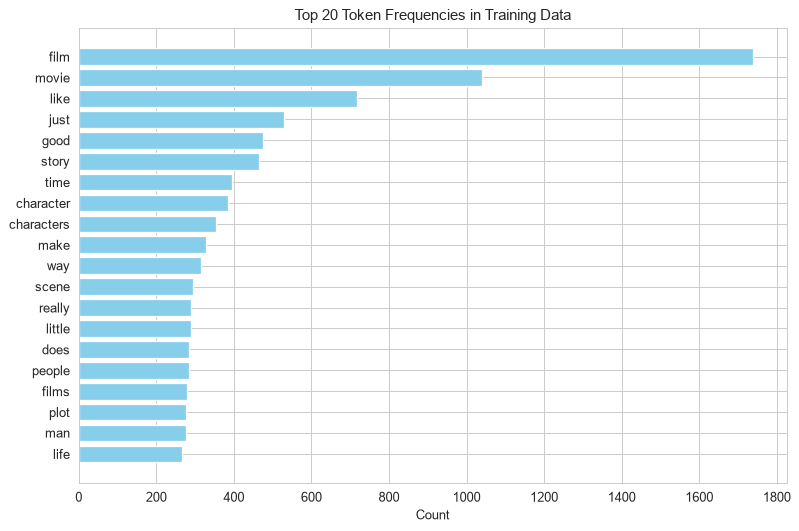

film          1739
movie         1039
like           717
just           530
good           475
story          464
time           396
character      384
characters     354
make           328


In [4]:
# Visualisasi 20 token paling sering di data latih
feature_names = vectorizer.get_feature_names_out()
counts = np.asarray(X_train_vect.sum(axis=0)).ravel()   # jumlah per kolom tanpa .toarray()

top_n = 20
sorted_indices = np.argsort(counts)[::-1]
top_feature_names = feature_names[sorted_indices][:top_n]
top_counts = counts[sorted_indices][:top_n]

plt.figure(figsize=(9, 6))
plt.barh(top_feature_names, top_counts, color='skyblue')
plt.xlabel('Count')
plt.title(f'Top {top_n} Token Frequencies in Training Data')
ax = plt.gca()
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
ax.set_xlim(left=0)
ax.invert_yaxis()
plt.tight_layout()
plt.show()

print(pd.Series(top_counts, index=top_feature_names).head(10).to_string())

**Interpretasi:**


- Korpus `movie_reviews` berisi **2.000** ulasan (`neg`=0, `pos`=1). Subset 500 ulasan dibagi menjadi **350 latih / 150 uji** dengan proporsi kelas tetap seimbang (stratified).
- `CountVectorizer(stop_words='english')` membangun kosakata **18.881 token** hanya dari 350 dokumen latih. Matriks berukuran $350 \times 18.881$ (±6,6 juta sel) tetapi hanya **89.870** entri yang tak-nol — *density* **1,36%**. Itulah alasan scikit-learn mengembalikan `csr_matrix`: menyimpan matriks penuh akan membuang >98% memori untuk angka nol. Data uji di-*transform* ke 18.881 kolom yang sama; kata baru di data uji diabaikan.
- Token terbanyak setelah stop words dihapus adalah **film (1.739)**, **movie (1.039)**, **like (717)**, **just (530)**, **good (475)**, **story (464)**. Kata-kata ini wajar untuk ulasan film, tetapi justru muncul di ulasan positif maupun negatif sehingga daya pembedanya kecil. Frekuensi mentah tidak sama dengan informativitas. Masalah inilah yang diatasi TF-IDF pada resep berikutnya. Perhatikan juga bahwa *good* sering muncul dalam konteks negasi ("not good"), sesuatu yang tidak tertangkap oleh unigram.

## 9.2 Teknik Vektorisasi Teks

**Teori:**

Sebelum vektorisasi pun, komputer sudah merepresentasikan huruf sebagai angka melalui *encoding* (ASCII, Unicode/UTF-8). Namun kode karakter tidak membawa makna; vektorisasi bertujuan membuat representasi yang berguna bagi model.

**1. Bag of Words (BoW).** Dokumen direpresentasikan sebagai multiset kata — urutan dan tata bahasa diabaikan. Vektor dokumen berisi frekuensi mentah $\operatorname{tf}(t,d)$ (persis keluaran `CountVectorizer`). Kelemahan: kata umum yang muncul di hampir semua dokumen mendominasi, dan dokumen panjang memiliki norma besar.

**2. TF-IDF** (*Term Frequency – Inverse Document Frequency*). Bobot setiap term dikoreksi oleh kelangkaannya di seluruh korpus:

$$
\operatorname{tfidf}(t,d) = \operatorname{tf}(t,d)\cdot \operatorname{idf}(t), \qquad
\operatorname{idf}(t) = \ln\frac{1+n}{1+\operatorname{df}(t)} + 1 ,
$$

dengan $n$ = jumlah dokumen dan $\operatorname{df}(t)$ = banyaknya dokumen yang memuat $t$. Rumus di atas adalah versi *smooth* default scikit-learn (`smooth_idf=True`; "+1" di penyebut seolah ada satu dokumen tambahan yang memuat semua term sehingga tidak ada pembagian nol, dan "+1" di akhir agar term yang ada di semua dokumen tidak berbobot nol). Setelah itu setiap baris dinormalisasi L2: $\mathbf{x}_d \leftarrow \mathbf{x}_d/\lVert \mathbf{x}_d\rVert_2$ sehingga panjang dokumen tidak berpengaruh dan *dot product* dua dokumen = **cosine similarity**. Term yang sering di satu dokumen tetapi jarang di korpus mendapat bobot tinggi — itulah term yang *distinctive*.

Opsi berguna: `sublinear_tf=True` (pakai $1+\ln \operatorname{tf}$), `min_df`/`max_df` (buang term terlalu jarang/sering), `ngram_range`.

**3. Word embeddings** (Word2Vec, GloVe, FastText, atau embedding dari model *transformer*). Setiap kata dipetakan ke vektor padat berdimensi kecil (mis. 100–768) yang dipelajari sedemikian rupa sehingga kata bermakna mirip berdekatan (*king* − *man* + *woman* ≈ *queen*). Berbeda dengan BoW/TF-IDF yang *sparse*, berdimensi $|V|$, dan memperlakukan setiap kata saling ortogonal (*cat* dan *kitten* sama jauhnya dengan *cat* dan *car*). scikit-learn tidak menyediakan embedding; biasanya dipakai pustaka seperti gensim atau sentence-transformers, lalu vektor rata-ratanya diumpankan ke model scikit-learn.

**Kapan memakai apa?** BoW/TF-IDF + model linear adalah *baseline* yang sangat kuat, cepat, dan dapat ditafsirkan untuk klasifikasi topik/sentimen. Embedding unggul ketika data sedikit tetapi semantik penting, atau untuk tugas kemiripan makna.

Dataset: korpus NLTK `reuters` (10.788 berita, ±1,3 juta kata, 90 kategori; dokumen dapat memiliki beberapa kategori, dan mengikuti buku kita hanya mengambil kategori pertama). Data dibagi 50/50.

In [5]:
# Memuat korpus Reuters dari NLTK
doc_ids = reuters.fileids()
texts = [reuters.raw(doc_id) for doc_id in doc_ids]
labels = [reuters.categories(doc_id)[0] for doc_id in doc_ids]   # kategori pertama saja

X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)
print('Jumlah dokumen :', len(texts), '| jumlah kategori (label pertama):', len(set(labels)))
print('Train / Test   :', len(X_train), '/', len(X_test))
print('5 kategori terbanyak:', Counter(labels).most_common(5))

Jumlah dokumen : 10788 | jumlah kategori (label pertama): 79
Train / Test   : 5394 / 5394
5 kategori terbanyak: [('earn', 3926), ('acq', 2369), ('crude', 552), ('interest', 453), ('money-fx', 362)]


In [6]:
# Bag of Words
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

# TF-IDF
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print('BoW    train shape :', X_train_bow.shape, '| dtype:', X_train_bow.dtype)
print('TF-IDF train shape :', X_train_tfidf.shape, '| dtype:', X_train_tfidf.dtype)

# Bandingkan representasi satu dokumen pada kedua skema
d = 0
row_bow = X_train_bow[d].toarray().ravel()
row_tfidf = X_train_tfidf[d].toarray().ravel()
vocab = bow_vectorizer.get_feature_names_out()
top_bow = np.argsort(row_bow)[::-1][:8]
cmp = pd.DataFrame({'term': vocab[top_bow],
                    'count (BoW)': row_bow[top_bow],
                    'tfidf': row_tfidf[top_bow].round(3),
                    'idf': tfidf_vectorizer.idf_[top_bow].round(2)})
print(f'\nDokumen latih #{d}: 8 term dengan count tertinggi')
display(cmp)
print('Norma L2 baris TF-IDF =', round(float(np.linalg.norm(row_tfidf)), 4))
top_tfidf = np.argsort(row_tfidf)[::-1][:8]
print('8 term dengan bobot TF-IDF tertinggi:', list(vocab[top_tfidf]))

BoW    train shape : (5394, 22864) | dtype: int64
TF-IDF train shape : (5394, 22864) | dtype: float64

Dokumen latih #0: 8 term dengan count tertinggi


,term,count (BoW),tfidf,idf
0,the,31,0.299,1.44
1,to,20,0.193,1.44
2,of,13,0.117,1.34
3,and,12,0.118,1.47
4,said,12,0.117,1.46
5,stock,11,0.223,3.04
6,bank,10,0.204,3.05
7,in,9,0.091,1.50


Norma L2 baris TF-IDF = 1.0
8 term dengan bobot TF-IDF tertinggi: ['the', 'stock', 'bank', 'to', 'japan', 'prices', 'discount', 'collapse']


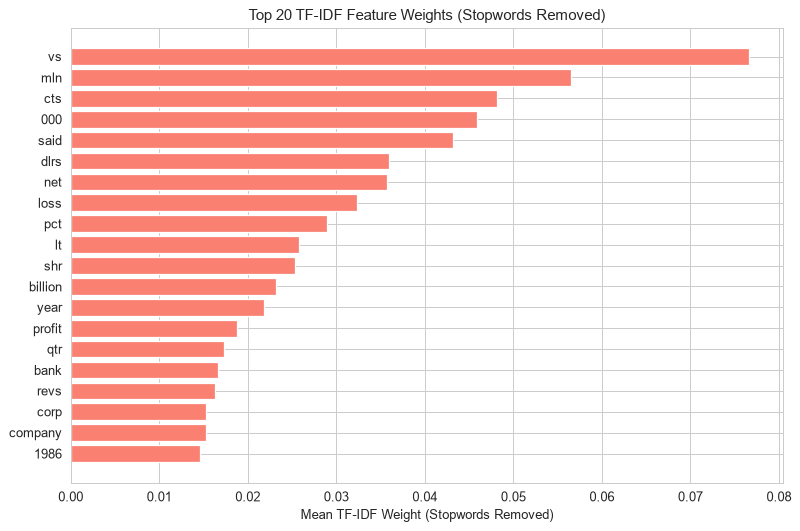

vs      0.0766
mln     0.0565
cts     0.0482
000     0.0459
said    0.0431
dlrs    0.0360
net     0.0357
loss    0.0323
pct     0.0290
lt      0.0258


In [7]:
# Visualisasi 20 term dengan rata-rata bobot TF-IDF tertinggi (stop words dihapus)
vis_tfidf_vectorizer = TfidfVectorizer(stop_words='english')
vis_X_train_tfidf = vis_tfidf_vectorizer.fit_transform(X_train)

feature_names = vis_tfidf_vectorizer.get_feature_names_out()
tfidf_means = np.asarray(vis_X_train_tfidf.mean(axis=0)).ravel()   # tanpa .toarray()

N = min(20, len(feature_names))
top_idx = np.argsort(tfidf_means)[-N:]

plt.figure(figsize=(9, 6))
plt.barh(feature_names[top_idx], tfidf_means[top_idx], color='salmon')
plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
plt.title(f'Top {N} TF-IDF Feature Weights (Stopwords Removed)')
plt.tight_layout()
plt.show()

print(pd.Series(tfidf_means[top_idx][::-1], index=feature_names[top_idx][::-1]).round(4).head(10).to_string())

**Interpretasi:**


- Korpus Reuters berisi **10.788** berita. Dengan mengambil kategori pertama saja, ada **79** label berbeda yang sangat tidak seimbang: *earn* (3.926) dan *acq* (2.369) mencakup ±58% data, sementara banyak kategori hanya punya beberapa dokumen. Split 50/50 menghasilkan 5.394 dokumen latih.
- BoW dan TF-IDF memiliki **kosakata yang sama (22.864 term)**. Bedanya ada pada isinya: BoW berisi bilangan bulat (`int64`), sedangkan TF-IDF berisi bobot real (`float64`) yang ternormalisasi L2 (norma baris dokumen #0 = **1,0**).
- Tabel dokumen #0 memperlihatkan efek IDF dengan jelas. *the* muncul **31** kali, sedangkan *stock* **11** kali (rasio count ±2,8×). Namun idf *the* hanya **1,44** karena *the* muncul di hampir semua dokumen, sedangkan idf *stock* **3,04**. Hasilnya, bobot TF-IDF keduanya hanya berbeda ±1,3× (**0,299** vs **0,223**). Kata *stock*, *bank*, *japan*, *discount*, dan *collapse* naik ke daftar teratas TF-IDF dan langsung menggambarkan isi berita (kejatuhan saham bank di Jepang). Karena vectorizer pertama tidak membuang stop words, *the* dan *to* masih ikut muncul.
- Pada plot rata-rata TF-IDF (stop words dihapus), term teratas adalah **vs (0,077)**, **mln (0,057)**, **cts (0,048)**, **000**, **said**, **dlrs**, **net**, **loss**, **pct**. Ini adalah singkatan khas laporan laba Reuters ("Net profit 5 mln dlrs vs 3 mln dlrs, 12 cts a share"). Pola ini mencerminkan dominasi kategori *earn*. Term seperti ini sangat berguna untuk klasifikasi topik walaupun bukan kata "bermakna" bagi manusia.

## 9.3 Ekstraksi Fitur dari Teks

**Teori:**

BoW/TF-IDF unigram kehilangan informasi urutan dan struktur. Ekstraksi fitur menambahkan informasi tersebut:

**N-gram.** Barisan $n$ token berurutan yang saling tumpang-tindih. Kalimat "*not a good movie*" memiliki bigram *not a*, *a good*, *good movie*. Unigram *good* menyesatkan untuk sentimen, tetapi bigram *not good* menangkap negasi. Di scikit-learn: `CountVectorizer(ngram_range=(1, 2))` menghasilkan unigram + bigram. Jumlah n-gram tumbuh sangat cepat (kosakata bigram bisa 5–10× unigram), sehingga biasanya dikombinasikan dengan `min_df` atau `max_features`. Ada pula **character n-gram** (`analyzer='char_wb'`) yang tahan terhadap salah ketik dan morfologi.

**Part-of-Speech (POS) tagging.** Memberi label kelas kata pada setiap token: kata benda (`NN`, `NNS`, `NNP` untuk nama diri), kata kerja (`VB`, `VBD`, `VBZ`, ...), kata sifat (`JJ`), kata keterangan (`RB`), preposisi (`IN`), determiner (`DT`), dll. (tagset *Penn Treebank*). NLTK memakai **averaged perceptron tagger** — model linear yang memprediksi tag dari fitur kontekstual (kata, sufiks, tag sebelumnya). POS berguna sebagai fitur sintaksis (mis. proporsi kata sifat untuk sentimen) atau untuk memfilter token (hanya ambil kata benda untuk topik).

**Named Entity Recognition (NER).** Mengidentifikasi frasa yang merujuk ke entitas: `PERSON`, `ORGANIZATION`, `GPE` (geo-politik/lokasi), tanggal, nilai uang, dll. Di NLTK, `nltk.ne_chunk` (*maxent chunker*) bekerja di atas hasil POS tagging. Entitas dapat dijadikan fitur (mis. "berita menyebut nama perusahaan X") atau untuk anonimisasi. Model NER modern (spaCy, transformer) jauh lebih akurat daripada chunker NLTK.

**Alur:** teks → tokenisasi (`word_tokenize`, berbasis model Punkt) → POS tagging → (opsional) NER chunking. Fitur-fitur ini lalu dapat digabung dengan matriks n-gram (mis. lewat `FeatureUnion`/`ColumnTransformer`).

Dataset: mengikuti buku, hanya 2 kalimat pertama dari 2 kategori pertama korpus Brown (*adventure* dan *belles_lettres*) — sengaja sangat kecil agar keluaran tagging dapat dibaca. Dengan `test_size=0.5`, ada 2 kalimat latih dan 2 kalimat uji.

In [8]:
texts, labels = [], []
categories_to_use = brown.categories()[:2]
num_sents_per_category = 2

for i, category in enumerate(categories_to_use):
    category_sents = brown.sents(categories=category)
    for sent_tokens in category_sents[:num_sents_per_category]:
        texts.append(' '.join(sent_tokens))
        labels.append(i)

X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)
print('Kategori:', categories_to_use)
for t, l in zip(texts, labels):
    print(l, '|', t)

Kategori: ['adventure', 'belles_lettres']
0 | Dan Morgan told himself he would forget Ann Turner .
0 | He was well rid of her .
1 | Northern liberals are the chief supporters of civil rights and of integration .
1 | They have also led the nation in the direction of a welfare state .


In [9]:
# N-gram (unigram + bigram)
ngram_vectorizer = CountVectorizer(ngram_range=(1, 2))
X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)
ngram_names = ngram_vectorizer.get_feature_names_out()
n_bi = sum(' ' in f for f in ngram_names)
print(f'Jumlah fitur n-gram: {len(ngram_names)} ({len(ngram_names) - n_bi} unigram + {n_bi} bigram)')
print('Contoh bigram:', [f for f in ngram_names if ' ' in f][:8])
print('Token uji yang dikenali (nnz X_test_ngram):', X_test_ngram.nnz)

# POS tagging dengan NLTK
print('\n--- POS Tagging of Tokens and N-grams in Training Sentences ---')
for i, text in enumerate(X_train):
    print(f'\nOriginal Sentence {i+1}: "{text}"')
    tokens = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(tokens)
    print('  Tagged Tokens (Unigrams):')
    print('    ' + ' '.join(f'{tok}/{tag}' for tok, tag in pos_tags))
    if len(pos_tags) >= 2:
        print('  Tagged Bigrams:')
        for (w1, t1), (w2, t2) in nltk_ngrams(pos_tags, 2):
            print(f'    {w1}/{t1} {w2}/{t2}')
print('\n--- End of POS Tagging Display ---')

Jumlah fitur n-gram: 39 (20 unigram + 19 bigram)
Contoh bigram: ['and of', 'ann turner', 'are the', 'chief supporters', 'civil rights', 'dan morgan', 'forget ann', 'he would']
Token uji yang dikenali (nnz X_test_ngram): 4

--- POS Tagging of Tokens and N-grams in Training Sentences ---

Original Sentence 1: "Northern liberals are the chief supporters of civil rights and of integration ."


  Tagged Tokens (Unigrams):
    Northern/NNP liberals/NNS are/VBP the/DT chief/JJ supporters/NNS of/IN civil/JJ rights/NNS and/CC of/IN integration/NN ./.
  Tagged Bigrams:
    Northern/NNP liberals/NNS
    liberals/NNS are/VBP
    are/VBP the/DT
    the/DT chief/JJ
    chief/JJ supporters/NNS
    supporters/NNS of/IN
    of/IN civil/JJ
    civil/JJ rights/NNS
    rights/NNS and/CC
    and/CC of/IN
    of/IN integration/NN
    integration/NN ./.

Original Sentence 2: "Dan Morgan told himself he would forget Ann Turner ."
  Tagged Tokens (Unigrams):
    Dan/NNP Morgan/NNP told/VBD himself/PRP he/PRP would/MD forget/VB Ann/NNP Turner/NNP ./.
  Tagged Bigrams:
    Dan/NNP Morgan/NNP
    Morgan/NNP told/VBD
    told/VBD himself/PRP
    himself/PRP he/PRP
    he/PRP would/MD
    would/MD forget/VB
    forget/VB Ann/NNP
    Ann/NNP Turner/NNP
    Turner/NNP ./.

--- End of POS Tagging Display ---


In [10]:
# Tambahan (tidak ada di kode buku): contoh Named Entity Recognition dengan nltk.ne_chunk
for text in X_train:
    tree = nltk.ne_chunk(nltk.pos_tag(nltk.word_tokenize(text)))
    ents = [(' '.join(w for w, _ in st.leaves()), st.label())
            for st in tree if hasattr(st, 'label')]
    print('Kalimat :', text[:90], '...')
    print('Entitas :', ents if ents else '(tidak ada entitas terdeteksi)')
    print()

Kalimat : Northern liberals are the chief supporters of civil rights and of integration . ...
Entitas : [('Northern', 'GPE')]



Kalimat : Dan Morgan told himself he would forget Ann Turner . ...
Entitas : [('Dan', 'PERSON'), ('Morgan', 'PERSON'), ('Ann Turner', 'PERSON')]



[('NNP', 5), ('NNS', 3), ('JJ', 2), ('.', 2), ('NN', 1), ('VBD', 1), ('MD', 1), ('VB', 1)]


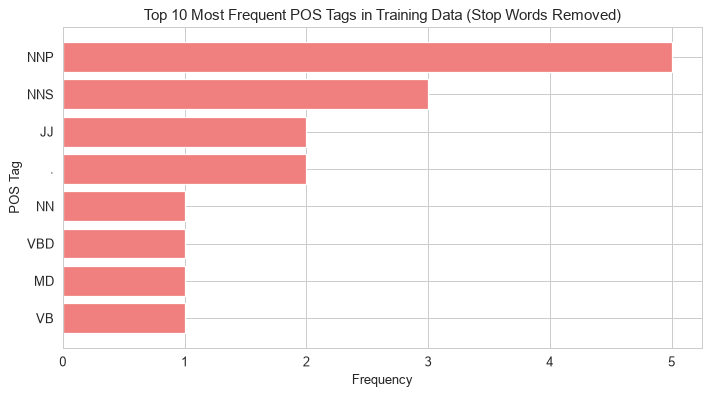

In [11]:
# Visualisasi frekuensi POS tag (stop words dihapus)
stop_words_set = set(stopwords.words('english'))
all_individual_pos_tags = []
for text_content in X_train:
    tokens = nltk.word_tokenize(text_content)
    filtered_tokens = [t for t in tokens if t.lower() not in stop_words_set]
    if not filtered_tokens:
        continue
    for _, tag in nltk.pos_tag(filtered_tokens):
        all_individual_pos_tags.append(tag)

top_10_pos_tags = Counter(all_individual_pos_tags).most_common(10)
print(top_10_pos_tags)
tags, counts = zip(*top_10_pos_tags)
plt.figure(figsize=(8, 4.5))
plt.barh(list(tags), list(counts), color='lightcoral')
plt.xlabel('Frequency')
plt.ylabel('POS Tag')
plt.title('Top 10 Most Frequent POS Tags in Training Data (Stop Words Removed)')
plt.gca().invert_yaxis()
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

**Interpretasi:**


- Dataset sengaja dibuat mini: 4 kalimat (2 *adventure*, 2 *belles_lettres*). Split 50/50 menempatkan kalimat "Northern liberals..." dan "Dan Morgan told himself..." di data latih.
- `CountVectorizer(ngram_range=(1,2))` menghasilkan **39 fitur** (**20 unigram + 19 bigram**), misalnya *dan morgan*, *ann turner*, *civil rights*, dan *chief supporters*. Bigram menyimpan frasa bermakna yang hilang bila kata dipisah. Dari dua kalimat uji, hanya **4** entri tak-nol yang dikenali (*he*, *of*, *the*), sehingga sebagian besar kosakata uji berada di luar kosakata latih. Ini ilustrasi ekstrem bahwa n-gram membutuhkan data latih yang banyak.
- POS tagger NLTK menandai kalimat dengan cukup akurat: *liberals/NNS* (kata benda jamak), *are/VBP*, *chief/JJ* (kata sifat), *told/VBD* (kata kerja lampau), *would/MD* (modal), *himself/PRP* (pronomina), dan nama orang *Dan/NNP Morgan/NNP*, *Ann/NNP Turner/NNP*. Ada satu kesalahan: *Northern* diberi tag NNP (nama diri) karena huruf kapital di awal kalimat. *Tagged bigrams* memperlihatkan pola sintaksis seperti JJ→NNS (*chief supporters*, *civil rights*).
- Contoh NER (tambahan) mendeteksi *Ann Turner* sebagai **PERSON** dengan benar. Namun *Dan* dan *Morgan* dipecah menjadi dua entitas PERSON terpisah, dan *Northern* keliru dianggap **GPE**. Kesalahan ini menunjukkan keterbatasan chunker maxent NLTK. Untuk produksi, model spaCy atau transformer jauh lebih andal.
- Grafik frekuensi POS (setelah stop words dihapus) didominasi **NNP (5)**, lalu **NNS (3)**, **JJ (2)**, dan **. (2)**. Karena kata fungsi (*the*, *of*, *he*) sudah dibuang, yang tersisa terutama kata isi: nama diri, kata benda, dan kata sifat. Dengan hanya 2 kalimat, distribusi ini tentu belum representatif. Tujuannya sekadar demonstrasi mekanisme.

## 9.4 Implementasi Model Klasifikasi Teks

**Teori:**

Setelah teks menjadi matriks TF-IDF $X$ (sangat berdimensi, *sparse*), hampir semua *classifier* scikit-learn dapat dipakai. Tiga yang paling klasik:

**1. Multinomial Naive Bayes.** Model generatif: dokumen dianggap dihasilkan dengan menarik kata-kata secara independen dari distribusi multinomial kelasnya. Dengan teorema Bayes dan asumsi *naive* (independensi kata diberikan kelas):

$$
\hat{y} = \arg\max_{c}\ \Big[\log P(c) + \sum_{j} x_{j}\,\log \hat\theta_{cj}\Big], \qquad
\hat\theta_{cj} = \frac{N_{cj} + \alpha}{N_c + \alpha |V|},
$$

dengan $N_{cj}$ total bobot term $j$ di dokumen kelas $c$ dan $\alpha$ = *Laplace/additive smoothing* (default 1) agar term yang tak pernah muncul tidak membuat probabilitas nol. Pelatihannya hanya menghitung frekuensi → sangat cepat, cocok untuk $|V|$ besar dan data kecil. Kelemahan: asumsi independensi menyebabkan probabilitas *over-confident*, dan dengan smoothing besar relatif terhadap TF-IDF yang kecil, model cenderung condong ke kelas mayoritas (prior).

**2. Support Vector Machine (`SVC`).** Mencari *hyperplane* dengan margin maksimum:
$\min_{\mathbf w,b} \tfrac12\lVert\mathbf w\rVert^2 + C\sum_i \xi_i$ s.t. $y_i(\mathbf w^\top\phi(\mathbf x_i)+b)\ge 1-\xi_i$. Default `SVC` memakai kernel RBF dan strategi multikelas **One-vs-One**. Untuk teks, data berdimensi tinggi biasanya sudah hampir terpisah linear, sehingga `LinearSVC` / kernel linear sering sama baik dan jauh lebih cepat.

**3. Regresi logistik (multinomial).** Model diskriminatif yang memodelkan $P(y=c\mid\mathbf x) = \operatorname{softmax}(W\mathbf x + \mathbf b)_c$, dilatih dengan *cross-entropy* + regularisasi L2 ($C=1$ default). Memberikan probabilitas yang terkalibrasi cukup baik dan koefisien per kata yang dapat ditafsirkan.

**Catatan:** model diskriminatif linear (LR, SVM linear) biasanya mengungguli NB ketika data cukup banyak; NB unggul pada data sangat sedikit. Untuk data dengan banyak kelas dan sedikit dokumen per kelas, semua model akan kesulitan.

Dataset: seluruh korpus Brown — 500 dokumen (±2.000 kata/dokumen) dari **15 genre** (*adventure*, *news*, *romance*, *science_fiction*, dst.), dibagi 50/50 terstratifikasi. Ini masalah multikelas yang sulit: hanya ±3–40 dokumen latih per kelas.

In [12]:
document_ids = brown.fileids()
texts = [' '.join(brown.words(file_id)) for file_id in document_ids]
raw_labels = [brown.categories(file_id)[0] for file_id in document_ids]

unique_raw_labels = sorted(list(set(raw_labels)))
label_to_int_mapping = {label: i for i, label in enumerate(unique_raw_labels)}
labels = [label_to_int_mapping[label] for label in raw_labels]

X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.5, stratify=labels, random_state=2024)

print('Jumlah dokumen:', len(texts), '| jumlah kelas:', len(unique_raw_labels))
print(pd.Series(raw_labels).value_counts().to_string())

Jumlah dokumen: 500 | jumlah kelas: 15
learned            80
belles_lettres     75
lore               48
news               44
hobbies            36
government         30
fiction            29
adventure          29
romance            29
editorial          27
mystery            24
reviews            17
religion           17
humor               9
science_fiction     6


In [13]:
# TF-IDF
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)
print('X_train_vect shape:', X_train_vect.shape)

# Tiga model
nb_clf = MultinomialNB().fit(X_train_vect, y_train)
svm_clf = SVC(random_state=2024).fit(X_train_vect, y_train)
lr_clf = LogisticRegression(random_state=2024, max_iter=1000).fit(X_train_vect, y_train)

def styled_report(y_true, y_pred, target_names=None):
    rep = classification_report(y_true, y_pred, target_names=target_names,
                                output_dict=True, zero_division=0)
    df = pd.DataFrame(rep).transpose()
    return (df.style
              .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
              .format({'precision': '{:.3f}', 'recall': '{:.3f}',
                       'f1-score': '{:.3f}', 'support': '{:.0f}'}))

models = {'Naive Bayes': nb_clf, 'SVM': svm_clf, 'Logistic Regression': lr_clf}
for name, model in models.items():
    y_pred = model.predict(X_test_vect)
    print(f'{name} Classification Report:')
    display(styled_report(y_test, y_pred, target_names=unique_raw_labels))
    print()

X_train_vect shape: (250, 30682)


Naive Bayes Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,15
belles_lettres,0.173,1.000,0.295,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.556,0.500,0.526,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


SVM Classification Report:


,precision,recall,f1-score,support
adventure,0.400,0.133,0.200,15
belles_lettres,0.236,0.946,0.378,37
editorial,0.000,0.000,0.000,14
fiction,0.312,0.357,0.333,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.424,0.700,0.528,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12



Logistic Regression Classification Report:


,precision,recall,f1-score,support
adventure,1.000,0.067,0.125,15
belles_lettres,0.231,0.919,0.370,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,1.000,0.056,0.105,18
humor,0.000,0.000,0.000,4
learned,0.377,0.725,0.496,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


Naive Bayes          accuracy = 0.228 | macro-F1 = 0.055 | kelas yang diprediksi = 2/15


SVM                  accuracy = 0.332 | macro-F1 = 0.160 | kelas yang diprediksi = 6/15
Logistic Regression  accuracy = 0.324 | macro-F1 = 0.146 | kelas yang diprediksi = 7/15


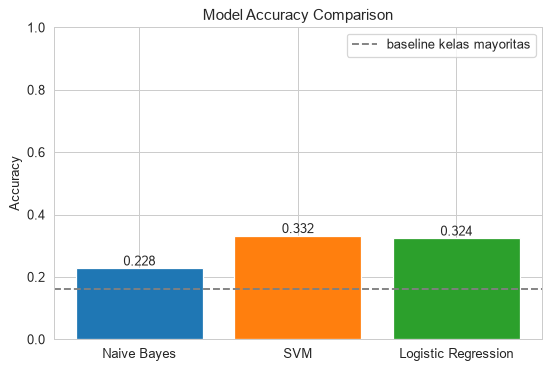

In [14]:
# Perbandingan akurasi + jumlah kelas berbeda yang benar-benar diprediksi
model_accuracies = {}
for name, model in models.items():
    y_pred = model.predict(X_test_vect)
    model_accuracies[name] = accuracy_score(y_test, y_pred)
    print(f'{name:20s} accuracy = {model_accuracies[name]:.3f} | '
          f'macro-F1 = {f1_score(y_test, y_pred, average="macro", zero_division=0):.3f} | '
          f'kelas yang diprediksi = {len(set(y_pred))}/15')

plt.figure(figsize=(7, 4.5))
bars = plt.bar(model_accuracies.keys(), model_accuracies.values(), color=['tab:blue', 'tab:orange', 'tab:green'])
plt.bar_label(bars, fmt='%.3f')
plt.axhline(max(Counter(y_test).values()) / len(y_test), ls='--', c='gray', label='baseline kelas mayoritas')
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.legend()
plt.show()

**Interpretasi:**


- Korpus Brown sangat tidak seimbang: *learned* 80 dokumen dan *belles_lettres* 75, tetapi *humor* hanya 9 dan *science_fiction* 6. Setelah split 50/50, model hanya melihat **250** dokumen latih untuk **15** kelas (3–40 dokumen per kelas) dengan **30.682** fitur TF-IDF. Situasi ini sangat sulit: $p \gg n$, banyak kelas, dan data sedikit. Baseline "selalu tebak kelas mayoritas" (*learned*, 40/250) memberi akurasi **0,16** (garis putus-putus pada grafik).
- **Naive Bayes gagal total:** akurasi **0,228** dengan macro-F1 **0,055**, dan model hanya memprediksi **2 dari 15 kelas** (214 dari 250 dokumen uji diprediksi *belles_lettres*, sisanya *learned*). Penyebabnya, bobot TF-IDF bernilai sangat kecil (setiap baris ternormalisasi L2 atas ±30 ribu term), sehingga *smoothing* $\alpha=1$ jauh lebih besar daripada "count" sebenarnya. Akibatnya, distribusi $\hat\theta_{cj}$ semua kelas hampir seragam dan keputusan didominasi prior kelas. Recall *belles_lettres* = 1,000 tetapi precision-nya hanya 0,173. MultinomialNB biasanya bekerja jauh lebih baik dengan count mentah atau $\alpha$ yang lebih kecil (mis. 0,01).
- **SVM (RBF)** meraih akurasi tertinggi **0,332** (macro-F1 **0,160**, 6 kelas diprediksi). Contoh hasil yang baik: *news* precision **1,000** / recall 0,409 (F1 0,581) dan *learned* F1 0,528. **Regresi logistik** hampir setara (**0,324**, macro-F1 **0,146**, 7 kelas) dan menjadi yang terbaik pada *romance* (F1 **0,621**).
- Ketiga model tetap condong ke dua kelas besar (*belles_lettres* dan *learned*), sementara kelas kecil seperti *humor*, *religion*, *reviews*, dan *science_fiction* tidak pernah diprediksi benar (F1 = 0). Akurasi ±0,33 memang lebih dari dua kali baseline, tetapi macro-F1 yang rendah menegaskan bahwa akurasi saja menyesatkan pada data tidak seimbang. Perbaikan yang masuk akal: `class_weight='balanced'`, `LinearSVC`, `sublinear_tf`/`min_df`, atau validasi silang alih-alih satu split kecil.

## 9.5 Strategi Klasifikasi Multikelas

**Teori:**

Banyak algoritma (SVM, regresi logistik biner, perceptron) pada dasarnya **biner**. Untuk $K>2$ kelas ada beberapa strategi reduksi:

**One-vs-Rest (OvR / One-vs-All).** Latih $K$ classifier biner; classifier ke-$k$ membedakan kelas $k$ vs semua kelas lain. Prediksi: kelas dengan skor (*decision function* / probabilitas) tertinggi,
$\hat y = \arg\max_k f_k(\mathbf x)$. Hanya $K$ model, setiap model melihat seluruh data. Kelemahan: setiap sub-masalah sangat **tidak seimbang** (1 kelas vs $K-1$ kelas) dan skor antar-model tidak selalu sebanding.

**One-vs-One (OvO).** Latih satu classifier untuk setiap **pasangan** kelas: $\binom{K}{2} = K(K-1)/2$ model (untuk 15 kelas = 105 model), masing-masing hanya dilatih pada data dua kelas tersebut. Prediksi melalui **voting**: setiap model memberi satu suara, kelas dengan suara terbanyak menang (seri dipecah dengan jumlah kepercayaan). Lebih banyak model, tetapi setiap model kecil dan seimbang — menguntungkan untuk algoritma yang skalanya superlinear terhadap $n$ (mis. SVM berkernel). Kelemahan: setiap model hanya melihat sebagian kecil data; dengan sedikit dokumen per kelas, model pasangan menjadi lemah.

**Multinomial/softmax langsung.** Beberapa model (regresi logistik multinomial, Naive Bayes, pohon keputusan, k-NN) secara alami menangani $K$ kelas. **Hierarchical classification** menyusun kelas dalam pohon (mis. *fiction* → {*romance*, *mystery*, ...}) dan mengklasifikasi bertahap.

Di scikit-learn: `OneVsRestClassifier(est)` dan `OneVsOneClassifier(est)` membungkus estimator biner apa pun. `SVC` memakai OvO secara internal; `LogisticRegression` modern memakai multinomial.

Kode buku memakai `LogisticRegression(solver='liblinear')` (solver biner yang efisien untuk data sparse) dibungkus kedua strategi, pada korpus Brown teks mentah (`brown.raw`, yang masih memuat tag POS seperti `/at`, `/nn`) dengan split 70/30.

In [15]:
file_ids = brown.fileids()
texts = [brown.raw(file_id) for file_id in file_ids]   # teks mentah ber-tag, mis. 'The/at Fulton/np-tl'
labels = [brown.categories(file_id)[0] for file_id in file_ids]

X_train, X_test, y_train, y_test = train_test_split(
    texts, labels, test_size=0.3, random_state=2024, stratify=labels)
print('Train / Test:', len(X_train), '/', len(X_test))
print('Cuplikan teks mentah:', texts[0][:120].split())

Train / Test: 350 / 150
Cuplikan teks mentah: ['The/at', 'Fulton/np-tl', 'County/nn-tl', 'Grand/jj-tl', 'Jury/nn-tl', 'said/vbd', 'Friday/nr', 'an/at', 'investigation/nn', 'of/in', "Atlanta's/np$"]


In [16]:
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# One-vs-Rest
ovr_clf = OneVsRestClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovr_clf.fit(X_train_vect, y_train)
y_pred_ovr = ovr_clf.predict(X_test_vect)

# One-vs-One
ovo_clf = OneVsOneClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovo_clf.fit(X_train_vect, y_train)
y_pred_ovo = ovo_clf.predict(X_test_vect)

print('Jumlah estimator OvR:', len(ovr_clf.estimators_), '| OvO:', len(ovo_clf.estimators_))

print('\nOne-vs-Rest Classification Report:')
display(styled_report(y_test, y_pred_ovr))
print('\nOne-vs-One Classification Report:')
display(styled_report(y_test, y_pred_ovo))

Jumlah estimator OvR: 15 | OvO: 105

One-vs-Rest Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.224,0.773,0.347,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.345,0.792,0.481,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7



One-vs-One Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.185,0.773,0.298,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.373,0.792,0.507,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7


In [17]:
summary = pd.DataFrame({
    'accuracy': [accuracy_score(y_test, y_pred_ovr), accuracy_score(y_test, y_pred_ovo)],
    'macro-F1': [f1_score(y_test, y_pred_ovr, average='macro', zero_division=0),
                 f1_score(y_test, y_pred_ovo, average='macro', zero_division=0)],
    'weighted-F1': [f1_score(y_test, y_pred_ovr, average='weighted', zero_division=0),
                    f1_score(y_test, y_pred_ovo, average='weighted', zero_division=0)],
    'kelas diprediksi': [len(set(y_pred_ovr)), len(set(y_pred_ovo))],
    'jumlah model': [len(ovr_clf.estimators_), len(ovo_clf.estimators_)],
}, index=['One-vs-Rest', 'One-vs-One'])
display(summary.round(3))

,accuracy,macro-F1,weighted-F1,kelas diprediksi,jumlah model
One-vs-Rest,0.307,0.121,0.205,5,15
One-vs-One,0.273,0.089,0.170,4,105


**Interpretasi:**


- Resep ini memakai `brown.raw`, yaitu teks yang masih menyertakan tag POS Brown (*The/at*, *Fulton/np-tl*). Tokenizer default memecah `The/at` menjadi token *the* dan *at*, sehingga kode tag (*nn*, *jj*, *vbd*, ...) ikut menjadi fitur TF-IDF. Secara tidak langsung, ini menambahkan fitur gaya sintaksis. Split 70/30 (350/150) berbeda dari resep 9.4, jadi angka keduanya tidak dapat dibandingkan langsung.
- Jumlah model sesuai teori: OvR melatih **15** classifier biner, sedangkan OvO melatih $\binom{15}{2}=$ **105** classifier pasangan.
- **One-vs-Rest** unggul dengan akurasi **0,307**, macro-F1 **0,121**, dan weighted-F1 **0,205** (5 kelas diprediksi). Kelas terbaiknya *news* (precision 0,875, recall 0,538, F1 **0,667**) dan *learned* (F1 0,481). OvR juga masih bisa menangkap *romance* (F1 0,316).
- **One-vs-One** lebih lemah: akurasi **0,273**, macro-F1 **0,089**, dan hanya **4** kelas yang diprediksi (*romance* hilang sama sekali). Setiap model OvO hanya dilatih pada dokumen dua kelas. Untuk pasangan kelas kecil, misalnya *science_fiction* (4 dokumen latih) vs *humor* (6), model dilatih dengan ±10 dokumen saja. Pada voting, kelas besar seperti *belles_lettres* (92 dari 150 prediksi) cenderung memenangkan banyak duel. Hasil ini sejalan dengan teori: keunggulan OvO muncul pada data yang **seimbang dan cukup besar**, bukan pada data kecil yang timpang seperti ini.
- Pada kedua strategi, banyak kelas tetap memiliki F1 = 0. Hambatan utamanya ada pada ukuran data per kelas, bukan pada pilihan strategi multikelas.

## 9.6 Evaluasi Model Teks

**Teori:**

Akurasi saja menyesatkan bila kelas tidak seimbang. Untuk setiap kelas $c$, dari *confusion matrix* didapat TP (benar diprediksi $c$), FP (salah diprediksi $c$), FN (kelas $c$ tetapi diprediksi lain):

$$
\text{Precision}_c = \frac{TP}{TP+FP}, \qquad
\text{Recall}_c = \frac{TP}{TP+FN}, \qquad
F_1 = 2\cdot\frac{\text{Precision}\cdot\text{Recall}}{\text{Precision}+\text{Recall}} .
$$

- **Precision** — dari semua yang diprediksi positif, berapa yang benar (penting bila *false positive* mahal, mis. filter spam yang membuang email penting).
- **Recall / sensitivity** — dari semua positif sebenarnya, berapa yang tertangkap (penting bila *false negative* mahal, mis. deteksi ujaran kebencian).
- **F1** — rata-rata harmonik; tinggi hanya bila keduanya tinggi.

**Agregasi multikelas** (`average=`): `macro` = rata-rata sederhana antar kelas (setiap kelas sama penting, sensitif terhadap kelas kecil); `weighted` = rata-rata berbobot *support*; `micro` = hitung TP/FP/FN global (untuk single-label sama dengan akurasi).

**Confusion matrix** $M_{ij}$ = banyaknya sampel kelas sebenarnya $i$ yang diprediksi $j$; diagonal = prediksi benar. Pola di luar diagonal menunjukkan kelas mana yang tertukar.

Evaluasi model teks generatif (LLM) jauh lebih kompleks (BLEU, ROUGE, *LLM-as-a-judge*, evaluasi manusia) dan di luar cakupan buku.

Dataset: `movie_reviews` lengkap (2.000 ulasan) yang diacak dengan `random.seed(2024)`, split 50/50, dan regresi logistik pada TF-IDF.

In [18]:
documents = [(list(movie_reviews.words(fileid)), category)
             for category in movie_reviews.categories()
             for fileid in movie_reviews.fileids(category)]

random.seed(2024)
random.shuffle(documents)

texts = [' '.join(words) for words, category in documents]
labels = [category for words, category in documents]

X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)
print('Train / Test:', len(X_train), '/', len(X_test), '| distribusi uji:', Counter(y_test))

Train / Test: 1000 / 1000 | distribusi uji: Counter({'pos': 505, 'neg': 495})


Precision: 0.8034174884733607
Recall: 0.803
F1 Score: 0.8029765558512367

Classification Report:


,precision,recall,f1-score,support
neg,0.791000,0.818200,0.804400,495.000000
pos,0.815600,0.788100,0.801600,505.000000
accuracy,0.803000,0.803000,0.803000,0.803000
macro avg,0.803300,0.803200,0.803000,1000.000000
weighted avg,0.803400,0.803000,0.803000,1000.000000


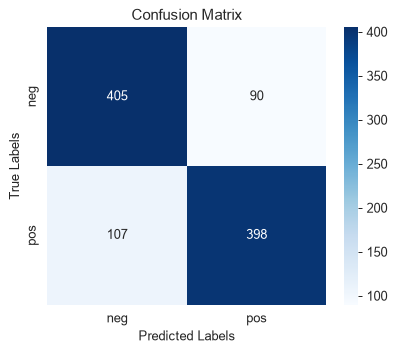

In [19]:
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

clf = LogisticRegression(random_state=2024)
clf.fit(X_train_vect, y_train)
y_pred = clf.predict(X_test_vect)

print('Precision:', precision_score(y_test, y_pred, average='weighted', zero_division=0))
print('Recall:', recall_score(y_test, y_pred, average='weighted', zero_division=0))
print('F1 Score:', f1_score(y_test, y_pred, average='weighted', zero_division=0))

report_dict = classification_report(y_test, y_pred, labels=clf.classes_, target_names=clf.classes_,
                                    output_dict=True, zero_division=0)
print('\nClassification Report:')
display(pd.DataFrame(report_dict).transpose().round(4).style.set_caption('Classification Report'))

cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [20]:
# Tambahan: kata dengan koefisien paling positif / negatif (interpretabilitas regresi logistik)
coef = clf.coef_.ravel()          # koefisien positif -> mendorong ke kelas clf.classes_[1] = 'pos'
names = vectorizer.get_feature_names_out()
order = np.argsort(coef)
print('Kelas positif model :', clf.classes_[1])
print('Top 15 kata -> neg  :', list(names[order[:15]]))
print('Top 15 kata -> pos  :', list(names[order[-15:][::-1]]))

Kelas positif model : pos
Top 15 kata -> neg  : ['bad', 'movie', 'this', 'plot', 'boring', 'worst', 'there', 'have', 'no', 'stupid', 'supposed', 'nothing', 'only', 'any', 'why']
Top 15 kata -> pos  : ['and', 'is', 'as', 'his', 'life', 'war', 'mulan', 'great', 'truman', 'very', 'of', 'men', 'true', 'many', 'jackie']


**Interpretasi:**


- Untuk sentimen biner dengan 1.000 ulasan latih, regresi logistik + TF-IDF mencapai **precision 0,803**, **recall 0,803**, dan **F1 0,803** (weighted). Nilai ini jauh di atas baseline 0,505 (proporsi *pos* di data uji: 505 *pos* vs 495 *neg*). Karena kelas hampir seimbang, nilai weighted ≈ macro ≈ akurasi (0,803).
- Per kelas, model sedikit lebih baik dalam *menangkap* ulasan negatif (recall *neg* **0,818** vs *pos* **0,788**) dan lebih *tepat* saat memprediksi positif (precision *pos* **0,816** vs *neg* **0,791**). F1 kedua kelas hampir sama (0,804 dan 0,802).
- Confusion matrix: **405** ulasan negatif dan **398** ulasan positif diklasifikasi benar. Sebanyak **90** ulasan negatif salah diprediksi positif (FP untuk kelas *pos*) dan **107** ulasan positif salah diprediksi negatif. Model sedikit lebih sering "pesimis".
- Koefisien model mudah ditafsirkan. Kata pendorong **negatif**: *bad*, *boring*, *worst*, *stupid*, *nothing*, *supposed*, *why*. Kata pendorong **positif**: *great*, *very*, *true*, *life*, *many*. Ada beberapa hal menarik. (1) *no* dan *any* adalah stop words yang ternyata informatif untuk sentimen, sehingga pada tugas sentimen stop words sebaiknya tidak dibuang sembarangan. (2) Nama spesifik seperti *mulan*, *truman*, dan *jackie* muncul sebagai indikator positif. Ini tanda model sedikit *overfit* pada judul film yang kebetulan diulas positif di data latih, bukan pola sentimen umum. (3) Kesalahan 20% kemungkinan berasal dari sarkasme, negasi ("not great"), dan ulasan yang campur aduk, yang tidak tertangkap oleh unigram. Bigram (`ngram_range=(1,2)`) biasanya menaikkan skor beberapa poin.

## Latihan (Practical Exercises with Text Processing)

Bagian ini mereproduksi notebook *Exercise Solutions* resmi: tiga latihan kecil yang merangkum alur chapter — pra-pemrosesan & vektorisasi, ekstraksi n-gram, serta membangun dan mengevaluasi classifier multikelas.

### Exercise 1: Preprocessing dan Vektorisasi Teks

In [21]:
texts = [
    "Data preprocessing is essential.",
    "Vectorization transforms text.",
    "Clean data improves model performance.",
    "Machine learning algorithms use numerical data."
]

# Pembersihan dasar: lowercase
texts_cleaned = [text.lower() for text in texts]

vectorizer = TfidfVectorizer()
X_ex1 = vectorizer.fit_transform(texts_cleaned)
print('Bentuk matriks TF-IDF:', X_ex1.shape)
display(pd.DataFrame(X_ex1.toarray(), columns=vectorizer.get_feature_names_out()).round(3))
vectorizer.get_feature_names_out()

Bentuk matriks TF-IDF: (4, 16)


,algorithms,clean,data,essential,improves,is,learning,machine,model,numerical,performance,preprocessing,text,transforms,use,vectorization
0,0.00,0.000,0.346,0.542,0.000,0.542,0.00,0.00,0.000,0.00,0.000,0.542,0.000,0.000,0.00,0.000
1,0.00,0.000,0.000,0.000,0.000,0.000,0.00,0.00,0.000,0.00,0.000,0.000,0.577,0.577,0.00,0.577
2,0.00,0.476,0.304,0.000,0.476,0.000,0.00,0.00,0.476,0.00,0.476,0.000,0.000,0.000,0.00,0.000
3,0.43,0.000,0.274,0.000,0.000,0.000,0.43,0.43,0.000,0.43,0.000,0.000,0.000,0.000,0.43,0.000


array(['algorithms', 'clean', 'data', 'essential', 'improves', 'is',
       'learning', 'machine', 'model', 'numerical', 'performance',
       'preprocessing', 'text', 'transforms', 'use', 'vectorization'],
      dtype=object)

### Exercise 2: Ekstraksi Fitur dengan N-gram

In [22]:
texts = [
    "Feature extraction is crucial.",
    "N-grams capture context.",
    "Models benefit from good features.",
    "Contextual information enhances classification."
]

ngram_vectorizer = CountVectorizer(ngram_range=(1, 2))
X_ex2 = ngram_vectorizer.fit_transform(texts)
print('Jumlah fitur n-gram:', X_ex2.shape[1])
ngram_vectorizer.get_feature_names_out()

Jumlah fitur n-gram: 28


array(['benefit', 'benefit from', 'capture', 'capture context',
       'classification', 'context', 'contextual',
       'contextual information', 'crucial', 'enhances',
       'enhances classification', 'extraction', 'extraction is',
       'feature', 'feature extraction', 'features', 'from', 'from good',
       'good', 'good features', 'grams', 'grams capture', 'information',
       'information enhances', 'is', 'is crucial', 'models',
       'models benefit'], dtype=object)

### Exercise 3: Membangun dan Mengevaluasi Classifier Multikelas

In [23]:
texts = [
    "This is an economic news article.",
    "Sports events are exciting.",
    "Technology advances rapidly.",
    "Politics affect global relations."
]
labels = ["Economy", "Sports", "Technology", "Politics"]

vectorizer = TfidfVectorizer()
X_vect = vectorizer.fit_transform(texts)

X_train, X_test, y_train, y_test = train_test_split(X_vect, labels, test_size=0.5, random_state=2024)
print('Label latih:', y_train, '| label uji:', y_test)

clf = LogisticRegression(random_state=2024)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
print('Prediksi   :', list(y_pred))
print(classification_report(y_test, y_pred, zero_division=0))

Label latih: ['Technology', 'Economy'] | label uji: ['Sports', 'Politics']
Prediksi   : [np.str_('Economy'), np.str_('Economy')]
              precision    recall  f1-score   support

     Economy       0.00      0.00      0.00       0.0
    Politics       0.00      0.00      0.00       1.0
      Sports       0.00      0.00      0.00       1.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0



**Interpretasi:**


- **Exercise 1:** empat kalimat menghasilkan kosakata **16 term** (matriks $4 \times 16$). Efek IDF terlihat jelas: *data* muncul di 3 dari 4 dokumen sehingga bobotnya kecil (**0,346 / 0,304 / 0,274**). Sebaliknya, term yang unik di satu dokumen mendapat bobot besar, misalnya *essential*, *is*, dan *preprocessing* = **0,542**. Kalimat "Vectorization transforms text." terdiri dari 3 term unik dengan bobot sama, yaitu $1/\sqrt{3} \approx$ **0,577**, akibat normalisasi L2. Lowercasing manual sebenarnya redundan karena `TfidfVectorizer` secara default sudah `lowercase=True`.
- **Exercise 2:** unigram + bigram menghasilkan **28 fitur**, misalnya *feature extraction*, *capture context*, dan *contextual information*. Kata "N-grams" berubah menjadi token *grams* saja karena pola token default mewajibkan minimal 2 karakter, sehingga huruf *n* dibuang. Detail tokenisasi seperti ini perlu diperhatikan (bisa diatur lewat `token_pattern`).
- **Exercise 3:** setiap kalimat mempunyai kelasnya sendiri (4 dokumen, 4 kelas). Split 50/50 menempatkan *Technology* dan *Economy* di data latih, sedangkan *Sports* dan *Politics* di data uji. Model hanya mengenal dua kelas latih, sehingga kedua dokumen uji diprediksi *Economy* dan **akurasi = 0,00**. Hasil ini memang tak terhindarkan: classifier tidak mungkin memprediksi kelas yang tidak pernah dilihatnya. Latihan ini (tanpa disengaja) menjadi pelajaran penting: klasifikasi multikelas memerlukan cukup contoh di **setiap** kelas dan split yang **terstratifikasi**. Tanpa `zero_division=0`, scikit-learn akan memberi `UndefinedMetricWarning`.

## Ringkasan Chapter 9


1. **Teks harus diubah menjadi angka.** Alurnya: normalisasi → tokenisasi → (opsional) hapus stop words → bangun kosakata → vektorisasi. Hasilnya adalah *document-term matrix* yang sangat sparse. Pada 350 ulasan film, kosakata berisi 18.881 token dengan density hanya 1,36%, sehingga scikit-learn menyimpannya sebagai `csr_matrix`. Vectorizer harus di-`fit` hanya pada data latih.
2. **BoW vs TF-IDF.** BoW menghitung frekuensi mentah sehingga kata umum (*film*, *movie*, *the*) mendominasi. TF-IDF mengalikan tf dengan $\operatorname{idf}(t)=\ln\frac{1+n}{1+\operatorname{df}(t)}+1$ lalu menormalisasi L2, sehingga term khas naik peringkat. Contohnya *stock*/*bank* (idf ≈ 3,0) vs *the* (idf 1,44) pada Reuters. *Word embeddings* memberi representasi padat dan semantik, tetapi berada di luar scikit-learn.
3. **Ekstraksi fitur linguistik.** N-gram menangkap urutan lokal (*civil rights*, *not good*) dengan konsekuensi kosakata membengkak. POS tagging (Penn Treebank: NN, VB, JJ, ...) dan NER (PERSON, ORGANIZATION, GPE) menambah informasi sintaksis dan semantik. Tagger/chunker NLTK cukup baik, tetapi tetap membuat kesalahan (*Northern* → NNP/GPE).
4. **Model klasifikasi teks.** Pada 15 genre Brown dengan hanya 250 dokumen latih, SVM (0,332) dan regresi logistik (0,324) mengungguli MultinomialNB (0,228). NB runtuh ke prior kelas karena smoothing $\alpha=1$ terlalu besar untuk bobot TF-IDF yang kecil. Macro-F1 semua model ≤ 0,16 karena kelas kecil tidak pernah diprediksi benar.
5. **Strategi multikelas.** OvR melatih $K$ model (15), sedangkan OvO melatih $K(K-1)/2$ model (105) dengan voting. Pada data kecil yang timpang, OvR lebih baik (akurasi 0,307, macro-F1 0,121) daripada OvO (0,273, 0,089), karena setiap model pasangan OvO hanya melihat sedikit dokumen.
6. **Evaluasi.** Precision, recall, F1, dan confusion matrix memberi gambaran yang lebih jujur daripada akurasi. Pilih `average='macro'` bila semua kelas sama penting dan `weighted` bila ingin mencerminkan distribusi kelas. Pada sentimen `movie_reviews`, regresi logistik + TF-IDF mencapai F1 0,803 (405/398 benar, 90 FP, 107 FN), dan koefisiennya mudah ditafsirkan (*bad*, *worst*, *boring* vs *great*, *very*, *true*).
7. **Pelajaran praktis.** Gunakan split terstratifikasi dan pastikan setiap kelas memiliki cukup contoh (Exercise 3 menghasilkan akurasi 0 karena kelas uji tidak pernah dilihat). Jangan membuang stop words begitu saja untuk tugas sentimen (*no*, *any* ternyata informatif). Waspadai juga *overfitting* pada nama/entitas spesifik.